# From Yield Curves to Bond Prices
*A small numerical study with the Vasicek model*

This notebook contains the Python calculations used in the short paper. I start with the DNB yield curve from 31 October 2022, fit the Vasicek model, simulate interest rates, and price a bond option. Finally, I compare the fitted curve with Nelson–Siegel.

The calculations follow the original Valuation and Risk Management assignment. I have put them together so each section can be run in order.

## 1. Starting with the yield curve

The data contain spot yields for maturities from 1 to 100 years. DNB reports the yields in percentages, so I first divide by 100. From these rates, I calculate discount factors and one-year forward rates.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from pathlib import Path

# Load the CSV from the data folder.
file = Path('../data/dnb_yields_2022.csv')
if not file.exists():
    file = Path('data/dnb_yields_2022.csv')
data = np.genfromtxt(file, delimiter=',', names=True)
years = data['maturity_years']
observed = data['yield_percent'] / 100

discount = np.exp(-observed * years)
forward = np.log(discount[:-1] / discount[1:])  # One-year intervals

print('Highest spot yield:', round(100 * max(observed), 3), '%')
print('Maturity of highest yield:', years[np.argmax(observed)], 'years')

Highest spot yield: 3.085 %
Maturity of highest yield: 12.0 years


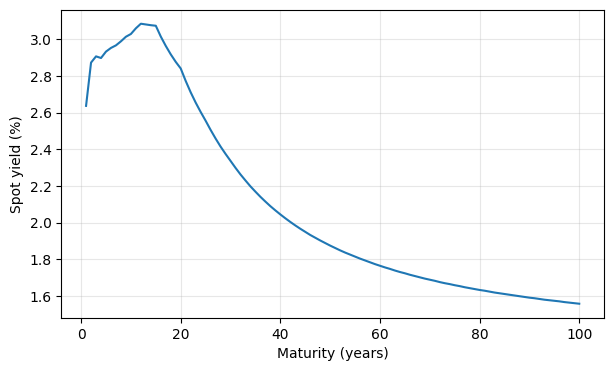

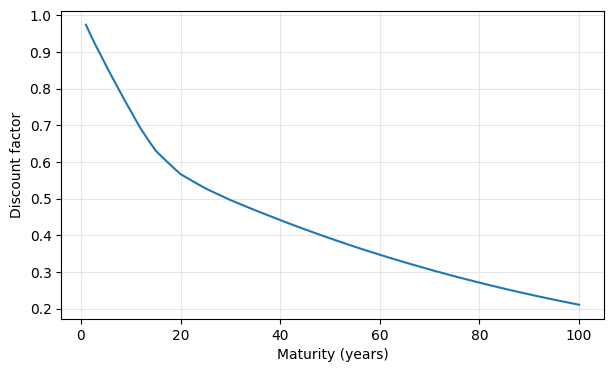

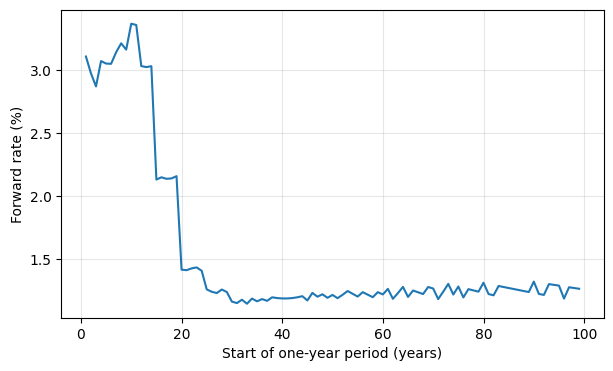

In [2]:
plt.figure(figsize=(7, 4))
plt.plot(years, 100 * observed)
plt.xlabel('Maturity (years)')
plt.ylabel('Spot yield (%)')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(years, discount)
plt.xlabel('Maturity (years)')
plt.ylabel('Discount factor')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(years[:-1], 100 * forward)
plt.xlabel('Start of one-year period (years)')
plt.ylabel('Forward rate (%)')
plt.grid(alpha=0.3)
plt.show()

The spot yield first rises and then falls for longer maturities. Next I check how closely a one-factor model can reproduce this shape.

## 2. Fitting the Vasicek model

Under the risk-neutral measure, the short rate is assumed to follow

$$dr_t = a(b-r_t)\,dt + \sigma\,dW_t^Q.$$

The model has a closed-form expression for spot yields. I estimate its four parameters by minimizing squared differences between observed and fitted yields, using the starting values and bounds from the assignment.

In [3]:
def vasicek_yield(t, a, b, sigma, r0):
    B = (1 - np.exp(-a * t)) / (a * t)
    long_yield = b - sigma**2 / (2 * a**2)
    return (long_yield + B * (r0 - long_yield)
            + sigma**2 * (1 - np.exp(-a * t))**2 / (4 * a**3 * t))


def error(parameters):
    a, b, sigma, r0 = parameters
    return vasicek_yield(years, a, b, sigma, r0) - observed

starting_values = [0.1, 0.03, 0.02, 0.027]
lower = [0.0001, -0.2, 0, -0.2]
upper = [5, 0.5, 0.5, 0.5]
result = least_squares(error, starting_values, bounds=(lower, upper))
a, b, sigma, r0 = result.x

fitted_vasicek = vasicek_yield(years, a, b, sigma, r0)
rmse_vasicek = 10000 * np.sqrt(np.mean((fitted_vasicek - observed)**2))

print(f'a = {a:.5f}')
print(f'b = {b:.5f}')
print(f'sigma = {sigma:.5f}')
print(f'r0 = {r0:.5f}')
print(f'RMSE = {rmse_vasicek:.2f} bp')

a = 0.10484
b = 0.07099
sigma = 0.03628
r0 = 0.02359
RMSE = 5.26 bp


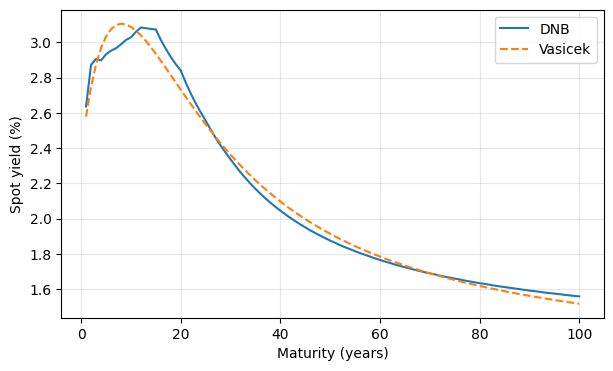

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(years, 100 * observed, label='DNB')
plt.plot(years, 100 * fitted_vasicek, '--', label='Vasicek')
plt.xlabel('Maturity (years)')
plt.ylabel('Spot yield (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The fitted curve captures the overall hump, but not all maturities equally well. The parameters are calibrated to this one observed curve; they are not estimates of how interest rates behave historically.

## 3. Simulating interest rates

I now simulate six paths over five years, using monthly steps. The Vasicek model has an exact transition formula, so I can use it instead of an Euler approximation. The seed is the same as in the assignment.

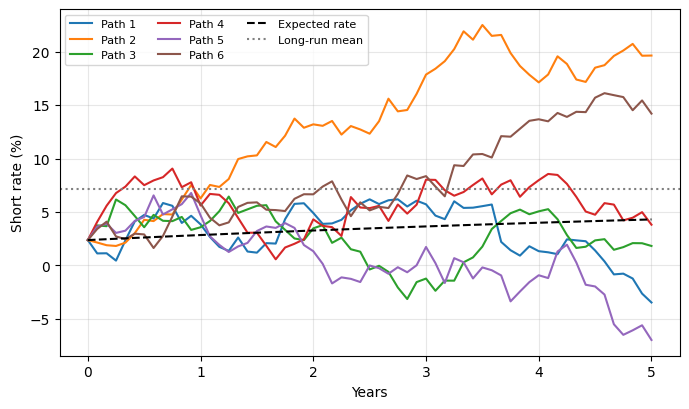

Expected rate after five years: 4.293 %
Simulated rates after five years (%): [-3.491 19.654  1.806  3.801 -7.004 14.211]


In [5]:
horizon = 5
steps = 60
paths_count = 6
dt = horizon / steps
times = np.linspace(0, horizon, steps + 1)

np.random.seed(20261115)
rates = np.zeros((steps + 1, paths_count))
rates[0, :] = r0

for i in range(steps):
    shocks = np.random.normal(size=paths_count)
    mean = b + (rates[i, :] - b) * np.exp(-a * dt)
    sd = sigma * np.sqrt((1 - np.exp(-2 * a * dt)) / (2 * a))
    rates[i + 1, :] = mean + sd * shocks

expected = b + (r0 - b) * np.exp(-a * times)

plt.figure(figsize=(8, 4.5))
for i in range(paths_count):
    plt.plot(times, 100 * rates[:, i], label=f'Path {i + 1}')
plt.plot(times, 100 * expected, 'k--', label='Expected rate')
plt.axhline(100 * b, linestyle=':', color='gray', label='Long-run mean')
plt.xlabel('Years')
plt.ylabel('Short rate (%)')
plt.legend(fontsize=8, ncol=3)
plt.grid(alpha=0.3)
plt.show()

print('Expected rate after five years:', round(100 * expected[-1], 3), '%')
print('Simulated rates after five years (%):', np.round(100 * rates[-1, :], 3))

The paths move differently because of the random shocks, while their conditional mean moves towards $b$. Since this model was fitted to the yield curve under $Q$, these simulations are **risk-neutral scenarios**, not forecasts of future market rates.

## 4. Pricing an option on a bond

Next I price European call and put options on a zero-coupon bond. The options expire after 0.75 years, the bond matures after 1 year, and the strike is 0.98.

For Vasicek, the short rate at option expiry and the integral of the short rate are jointly normally distributed. The original assignment uses this result to simulate discounted option payoffs directly.

In [6]:
option_time = 0.75
bond_time = 1.0
strike = 0.98
simulations = 200000

h = option_time
e = np.exp(-a * h)
mean_r = b + (r0 - b) * e
mean_i = b * h + (r0 - b) * (1 - e) / a
var_r = sigma**2 * (1 - e**2) / (2 * a)
var_i = sigma**2 / a**2 * (h - 2 * (1 - e) / a + (1 - e**2) / (2 * a))
covariance = sigma**2 * (1 - e)**2 / (2 * a**2)

rng = np.random.default_rng(20261115)
z1 = rng.normal(size=simulations)
z2 = rng.normal(size=simulations)

r_end = mean_r + np.sqrt(var_r) * z1
integrated_r = (mean_i + covariance / np.sqrt(var_r) * z1
                + np.sqrt(var_i - covariance**2 / var_r) * z2)

remaining = bond_time - option_time
bond_price = np.exp(-remaining * vasicek_yield(remaining, a, b, sigma, r_end))
discount_factor = np.exp(-integrated_r)

call_payoff = discount_factor * np.maximum(bond_price - strike, 0)
put_payoff = discount_factor * np.maximum(strike - bond_price, 0)
call = np.mean(call_payoff)
put = np.mean(put_payoff)
call_se = np.std(call_payoff, ddof=1) / np.sqrt(simulations)
put_se = np.std(put_payoff, ddof=1) / np.sqrt(simulations)

print('Call price:', round(call, 6), 'SE:', round(call_se, 8))
print('Put price: ', round(put, 6), 'SE:', round(put_se, 8))

Call price: 0.013048 SE: 1.611e-05
Put price:  0.000104 SE: 1.59e-06


A simple numerical check is put–call parity: the difference between call and put prices should match the difference between two discounted bond values.

In [7]:
p1 = np.exp(-bond_time * vasicek_yield(bond_time, a, b, sigma, r0))
p075 = np.exp(-option_time * vasicek_yield(option_time, a, b, sigma, r0))
parity = p1 - strike * p075

print('Call - Put:', round(call - put, 6))
print('Put-call parity:', round(parity, 6))
print('Difference:', round((call - put) - parity, 8))

Call - Put: 0.012944
Put-call parity: 0.012955
Difference: -1.097e-05


The difference is small relative to the Monte Carlo error. This checks that the numerical pricing is internally consistent, but it does not tell us whether the calibrated model gives accurate market option prices.

## 5. Comparing with Nelson–Siegel

Finally, I fit a Nelson–Siegel curve to the same data. This is a useful comparison because Nelson–Siegel is designed to describe the yield curve's shape, rather than specify interest-rate dynamics for option pricing.

In [8]:
def nelson_siegel(t, beta0, beta1, beta2, lam):
    part1 = (1 - np.exp(-lam * t)) / (lam * t)
    part2 = part1 - np.exp(-lam * t)
    return beta0 + beta1 * part1 + beta2 * part2


def ns_error(parameters):
    return nelson_siegel(years, *parameters) - observed

best_result = None
for starting_a in [0.02, 0.05, 0.1, 0.15, 0.3, 0.5]:
    result = least_squares(ns_error, [0.015, 0.01, 0.04, starting_a],
                           bounds=([-0.3, -0.5, -0.5, 0.00001],
                                   [0.5, 0.5, 0.5, 10]))
    if best_result is None or sum(result.fun**2) < sum(best_result.fun**2):
        best_result = result

beta0, beta1, beta2, lam = best_result.x
fitted_ns = nelson_siegel(years, beta0, beta1, beta2, lam)
rmse_ns = 10000 * np.sqrt(np.mean((fitted_ns - observed)**2))

print('Nelson-Siegel parameters:', np.round(best_result.x, 6))
print('Nelson-Siegel RMSE:', round(rmse_ns, 2), 'bp')
print('Vasicek RMSE:', round(rmse_vasicek, 2), 'bp')

Nelson-Siegel parameters: [0.011274 0.012541 0.04434  0.144763]
Nelson-Siegel RMSE: 4.95 bp
Vasicek RMSE: 5.26 bp


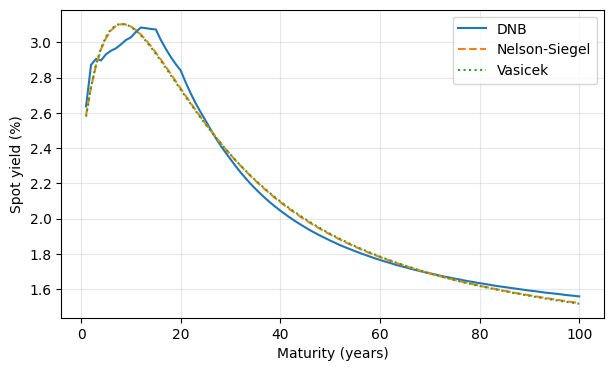

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(years, 100 * observed, label='DNB')
plt.plot(years, 100 * fitted_ns, '--', label='Nelson-Siegel')
plt.plot(years, 100 * fitted_vasicek, ':', label='Vasicek')
plt.xlabel('Maturity (years)')
plt.ylabel('Spot yield (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. What I take from this

The Vasicek model gives a reasonable fit and makes simulation and bond-option pricing straightforward. Nelson–Siegel fits the observed curve slightly better, but the static curve does not by itself give a stochastic pricing model.

The main point of this exercise is that **fitting today's prices** and **modelling future rates for pricing** are related, but different tasks.